# Quantum Error Correction: repetition code and rotated surface code with minimum-weight matching

## Problem
Physical qubits flip (bit-flip or phase-flip errors) with some probability $p$. Quantum error-correcting codes encode one logical qubit in many physical qubits so that the *logical* error rate $p_L$ can be made smaller than $p$. The key question is the **threshold**: below some $p_{th}$, increasing the code distance $d$ lowers $p_L$. This notebook estimates $p_L(p)$ by Monte Carlo for distance-3, 5 and 7 codes, and locates where the curves cross.

## Data
No external data set is needed: the input is the code geometry plus a simulated noise model. The noise model is the usual **code-capacity** one (independent bit-flip errors on each data qubit with probability $p$, perfect syndrome measurement), which is a standard benchmark for surface-code thresholds. The codes are constructed in the notebook:
* **Bit-flip repetition code**, distance $d$ ($d$ data qubits, $d-1$ parity checks).
* **Rotated planar surface code**, distance $d$ ($d^2$ data qubits, $d^2-1$ stabilisers, one logical qubit; $d=3,5,7$). Its parity checks and boundaries follow the standard rotated layout (Bravyi & Kitaev 1998; Tomita & Svore 2014).

## Method
Stabiliser checks $H_Z$ detect $X$ errors. The decoder finds a correction $c$ with the same syndrome as the error $e$ and the minimum number of flipped data qubits. This is **minimum-weight perfect matching (MWPM)**: the syndrome defects are matched in pairs, either to each other or to a code boundary, with cost equal to the shortest-path distance on the decoding graph. The matching is solved exactly with `networkx.max_weight_matching`, with boundary copies added in the standard way. The logical error is detected by a logical operator $L_Z$ that commutes with the stabilisers:

$$
\text{fail} = \big( L_Z \cdot (e + c) \big) \bmod 2 .
$$

Monte Carlo estimate: $\hat p_L = \frac{1}{N}\sum_i \text{fail}_i$, with standard error $\sqrt{\hat p_L(1-\hat p_L)/N}$.

Validation: for $d=3$ the failure probability is also computed exactly by enumerating all $2^9$ error patterns, and the repetition-code result is compared with the closed-form majority-vote formula $\sum_{k>d/2}\binom{d}{k}p^k(1-p)^{d-k}$.

In [1]:
import itertools, time
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from math import comb
import qiskit, qiskit_aer, scipy
from scipy.optimize import brentq

SEED = 7
rng = np.random.default_rng(SEED)
print("networkx", nx.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__)

networkx 3.6.1 | numpy 2.5.3 | scipy 1.18.0


In [2]:
# GF(2) linear algebra helpers
def gf2_rref(M):
    M = (np.array(M, dtype=np.uint8) % 2).copy()
    rows, cols = M.shape
    piv, r = [], 0
    for c in range(cols):
        if r >= rows:
            break
        pr = np.nonzero(M[r:, c])[0]
        if len(pr) == 0:
            continue
        pr = pr[0] + r
        M[[r, pr]] = M[[pr, r]]
        for rr in range(rows):
            if rr != r and M[rr, c]:
                M[rr] ^= M[r]
        piv.append(c); r += 1
    return M[:r], piv

def gf2_rank(M):
    return len(gf2_rref(M)[1])

def gf2_nullspace(M):
    R, piv = gf2_rref(M)
    n = M.shape[1]
    free = [c for c in range(n) if c not in piv]
    basis = []
    for f in free:
        v = np.zeros(n, dtype=np.uint8)
        v[f] = 1
        for i, pc in enumerate(piv):
            v[pc] = R[i, f]
        basis.append(v)
    return np.array(basis, dtype=np.uint8)

In [3]:
class MWPMCode:
    """A CSS-type bit-flip code: Z-type checks Hz (detect X errors), logical Z operator Lz, and an
    MWPM decoder on the decoding graph (checks = nodes, data qubits = edges, boundary = extra node)."""
    def __init__(self, name, Hz, Lz, distance):
        self.name, self.Hz, self.Lz, self.d = name, np.array(Hz, dtype=np.uint8), np.array(Lz, dtype=np.uint8), distance
        self.m, self.n = self.Hz.shape
        self.B = self.m                        # boundary node index
        G = nx.Graph()
        G.add_nodes_from(range(self.m + 1))
        self.edge_qubit = {}
        for q in range(self.n):
            stabs = np.nonzero(self.Hz[:, q])[0]
            if len(stabs) == 2:
                a, b = int(stabs[0]), int(stabs[1])
            elif len(stabs) == 1:
                a, b = int(stabs[0]), self.B
            else:
                raise ValueError("data qubit touches no check")
            key = frozenset((a, b))
            if key in self.edge_qubit:
                # Two qubits with identical check patterns differ by a weight-2 operator with trivial syndrome.
                # For distance >= 3 that operator is a stabiliser (not a logical), so keeping one edge is exact.
                self.n_parallel = getattr(self, "n_parallel", 0) + 1
                continue
            self.edge_qubit[key] = q
            G.add_edge(a, b, weight=1)
        self.G = G
        pred, dist = nx.floyd_warshall_predecessor_and_distance(G, weight="weight")
        self.pred, self.dist = pred, dist
        self.cache = {}

    def path_qubits(self, src, dst):
        path = [dst]
        while path[-1] != src:
            path.append(self.pred[src][path[-1]])
        path = path[::-1]
        flips = np.zeros(self.n, dtype=np.uint8)
        for x, y in zip(path[:-1], path[1:]):
            flips[self.edge_qubit[frozenset((x, y))]] ^= 1
        return flips

    def correction(self, syndrome):
        key = syndrome.tobytes()
        if key in self.cache:
            return self.cache[key]
        defects = [int(i) for i in np.nonzero(syndrome)[0]]
        corr = np.zeros(self.n, dtype=np.uint8)
        k = len(defects)
        if k:
            BIG = 10000
            M = nx.Graph()
            M.add_nodes_from(range(2 * k))
            for i in range(k):
                M.add_edge(i, k + i, weight=BIG - self.dist[defects[i]][self.B])
                for j in range(i + 1, k):
                    M.add_edge(i, j, weight=BIG - self.dist[defects[i]][defects[j]])
                    M.add_edge(k + i, k + j, weight=BIG)
            matching = nx.max_weight_matching(M, maxcardinality=True)
            for a, b in matching:
                a, b = min(a, b), max(a, b)
                if b < k:
                    corr ^= self.path_qubits(defects[a], defects[b])
                elif b == k + a:
                    corr ^= self.path_qubits(defects[a], self.B)
        self.cache[key] = corr
        return corr

    def logical_error_rate(self, p, shots, rng):
        E = (rng.random((shots, self.n)) < p).astype(np.uint8)
        S = ((E.astype(np.int64) @ self.Hz.T.astype(np.int64)) % 2).astype(np.uint8)
        uniq, inv = np.unique(S, axis=0, return_inverse=True)
        inv = inv.reshape(-1)
        Cu = np.array([self.correction(s) for s in uniq], dtype=np.uint8)
        R = E ^ Cu[inv]
        assert not np.any((R.astype(np.int64) @ self.Hz.T.astype(np.int64)) % 2), "residual syndrome nonzero"
        fail = ((R.astype(np.int64) @ self.Lz.astype(np.int64)) % 2).astype(bool)
        return fail.mean(), fail.sum()

def repetition_code(d):
    Hz = np.zeros((d - 1, d), dtype=np.uint8)
    for i in range(d - 1):
        Hz[i, i] = 1; Hz[i, i + 1] = 1
    Lz = np.zeros(d, dtype=np.uint8); Lz[0] = 1          # Z_0 anticommutes with the logical X^{otimes d}
    return MWPMCode(f"repetition d={d}", Hz, Lz, d)

def rotated_surface_code(d):
    """Rotated planar surface code: data qubits on a d x d grid; faces (i, j), 0<=i,j<=d.
    Interior faces have weight 4; boundary faces have weight 2. Z-type faces: (i+j) even."""
    n = d * d
    qidx = lambda r, c: r * d + c
    Xs, Zs = [], []
    for i in range(d + 1):
        for j in range(d + 1):
            qs = [qidx(r, c) for r in (i - 1, i) for c in (j - 1, j) if 0 <= r < d and 0 <= c < d]
            typ = "Z" if (i + j) % 2 == 0 else "X"
            if len(qs) == 4:
                keep = True
            elif len(qs) == 2 and i in (0, d):          # top/bottom boundary keeps X-type faces
                keep = typ == "X"
            elif len(qs) == 2 and j in (0, d):          # left/right boundary keeps Z-type faces
                keep = typ == "Z"
            else:
                keep = False
            if keep:
                (Zs if typ == "Z" else Xs).append(qs)
    Hz = np.zeros((len(Zs), n), dtype=np.uint8)
    Hx = np.zeros((len(Xs), n), dtype=np.uint8)
    for r, qs in enumerate(Zs):
        Hz[r, qs] = 1
    for r, qs in enumerate(Xs):
        Hx[r, qs] = 1
    assert len(Zs) + len(Xs) == d * d - 1, "wrong number of stabilisers"
    assert not np.any((Hx.astype(int) @ Hz.T.astype(int)) % 2), "X and Z stabilisers do not commute"
    assert gf2_rank(Hx) + gf2_rank(Hz) == n - 1, "not a single logical qubit"
    # logical Z: in the null space of Hx but not a Z-stabiliser
    Lz = None
    for v in gf2_nullspace(Hx):
        if gf2_rank(np.vstack([Hz, v])) > gf2_rank(Hz):
            Lz = v
            break
    assert Lz is not None
    return MWPMCode(f"surface d={d}", Hz, Lz, d), Hx

for d in [3, 5, 7]:
    code_obj, Hx_ = rotated_surface_code(d)
    print(f"Rotated surface code d={d}: {code_obj.n} data qubits, {code_obj.m} Z-checks, "
          f"{Hx_.shape[0]} X-checks, logical Z weight = {int(code_obj.Lz.sum())}, "
          f"decoding graph edges = {code_obj.G.number_of_edges()} "
          f"(qubits with identical check pattern merged: {getattr(code_obj, 'n_parallel', 0)})")
for d in [3, 5, 7]:
    rc = repetition_code(d)
    print(f"Repetition code d={d}: {rc.n} data qubits, {rc.m} checks, logical weight = {int(rc.Lz.sum())}")

Rotated surface code d=3: 9 data qubits, 4 Z-checks, 4 X-checks, logical Z weight = 3, decoding graph edges = 7 (qubits with identical check pattern merged: 2)
Rotated surface code d=5: 25 data qubits, 12 Z-checks, 12 X-checks, logical Z weight = 5, decoding graph edges = 21 (qubits with identical check pattern merged: 4)
Rotated surface code d=7: 49 data qubits, 24 Z-checks, 24 X-checks, logical Z weight = 7, decoding graph edges = 43 (qubits with identical check pattern merged: 6)
Repetition code d=3: 3 data qubits, 2 checks, logical weight = 1
Repetition code d=5: 5 data qubits, 4 checks, logical weight = 1
Repetition code d=7: 7 data qubits, 6 checks, logical weight = 1


In [4]:
# Sanity checks: the decoder returns a correction with the same syndrome, and corrects every single error
sc3, _ = rotated_surface_code(3)
ok = True
for q in range(sc3.n):
    e = np.zeros(sc3.n, dtype=np.uint8); e[q] = 1
    s = (sc3.Hz.astype(int) @ e) % 2
    c = sc3.correction(s.astype(np.uint8))
    if np.any((sc3.Hz.astype(int) @ c) % 2 != s) or ((e ^ c).astype(int) @ sc3.Lz.astype(int)) % 2:
        ok = False
print("d=3 surface code corrects every weight-1 X error:", ok)

# Exact failure probability of the d=3 surface code under the MWPM decoder: enumerate all 2^9 patterns
def exact_failure_probability(code_obj, p):
    total = 0.0
    n = code_obj.n
    fail_patterns = 0
    for bits in itertools.product([0, 1], repeat=n):
        e = np.array(bits, dtype=np.uint8)
        s = ((code_obj.Hz.astype(int) @ e.astype(int)) % 2).astype(np.uint8)
        c = code_obj.correction(s)
        r = e ^ c
        if ((r.astype(int) @ code_obj.Lz.astype(int)) % 2):
            total += p ** e.sum() * (1 - p) ** (n - e.sum())
            fail_patterns += 1
    return total, fail_patterns

P_EXACT_TEST = 0.1
pl_exact, nfail = exact_failure_probability(sc3, P_EXACT_TEST)
print(f"d=3 surface code, exact enumeration at p = {P_EXACT_TEST}: P_L = {pl_exact:.6f} "
      f"({nfail} of 512 error patterns fail)")
pl_mc, _ = sc3.logical_error_rate(P_EXACT_TEST, 200000, np.random.default_rng(SEED))
print(f"d=3 surface code, Monte Carlo (200000 shots) at p = {P_EXACT_TEST}: P_L = {pl_mc:.6f}")

d=3 surface code corrects every weight-1 X error: True
d=3 surface code, exact enumeration at p = 0.1: P_L = 0.119695 (256 of 512 error patterns fail)


d=3 surface code, Monte Carlo (200000 shots) at p = 0.1: P_L = 0.119015


In [5]:
# Repetition code: Monte Carlo vs the closed-form majority-vote result
def rep_exact(d, p):
    return sum(comb(d, k) * p ** k * (1 - p) ** (d - k) for k in range(d // 2 + 1, d + 1))

for d in [3, 5, 7]:
    rc = repetition_code(d)
    pl_ex, nf = exact_failure_probability(rc, 0.1)
    pl, _ = rc.logical_error_rate(0.1, 200000, np.random.default_rng(SEED + d))
    se = np.sqrt(pl * (1 - pl) / 200000)
    print(f"Repetition d={d} at p=0.10: enumeration {pl_ex:.5f} (closed form {rep_exact(d, 0.1):.5f}), "
          f"Monte Carlo {pl:.5f} +/- {se:.5f}")

Repetition d=3 at p=0.10: enumeration 0.02800 (closed form 0.02800), Monte Carlo 0.02702 +/- 0.00036


Repetition d=5 at p=0.10: enumeration 0.00856 (closed form 0.00856), Monte Carlo 0.00850 +/- 0.00021


Repetition d=7 at p=0.10: enumeration 0.00273 (closed form 0.00273), Monte Carlo 0.00259 +/- 0.00011


In [6]:
# Logical error rate vs physical error rate for d = 3, 5, 7 (surface code) and the repetition code
P_GRID = np.array([0.02, 0.04, 0.06, 0.07, 0.08, 0.09, 0.10, 0.11, 0.12, 0.14, 0.16])
SHOTS = 8000                                            # per (distance, p) for the surface code
REP_SHOTS = 20000
surf = {d: rotated_surface_code(d)[0] for d in [3, 5, 7]}
rep = {d: repetition_code(d) for d in [3, 5, 7]}

pl_surf = {d: np.zeros(len(P_GRID)) for d in surf}
err_surf = {d: np.zeros(len(P_GRID)) for d in surf}
pl_rep = {d: np.zeros(len(P_GRID)) for d in rep}
t0 = time.time()
for d, code_obj in surf.items():
    for i, p in enumerate(P_GRID):
        pl, _ = code_obj.logical_error_rate(p, SHOTS, np.random.default_rng(SEED * 1000 + 10 * d + i))
        pl_surf[d][i] = pl
        err_surf[d][i] = np.sqrt(max(pl * (1 - pl), 1e-12) / SHOTS)
    print(f"surface d={d}: done, {time.time() - t0:.1f} s elapsed, decoder cache size {len(code_obj.cache)}")
for d, code_obj in rep.items():
    for i, p in enumerate(P_GRID):
        pl, _ = code_obj.logical_error_rate(p, REP_SHOTS, np.random.default_rng(SEED * 2000 + 10 * d + i))
        pl_rep[d][i] = pl
print(f"repetition codes done, {time.time() - t0:.1f} s total")

print(f"{'p':>7s} " + " ".join(f"{'surf d=' + str(d):>12s}" for d in surf) + " " +
      " ".join(f"{'rep d=' + str(d):>10s}" for d in rep))
for i, p in enumerate(P_GRID):
    print(f"{p:7.3f} " + " ".join(f"{pl_surf[d][i]:12.5f}" for d in surf) + " " +
          " ".join(f"{pl_rep[d][i]:10.5f}" for d in rep))

surface d=3: done, 0.5 s elapsed, decoder cache size 16


surface d=5: done, 8.5 s elapsed, decoder cache size 3466


surface d=7: done, 167.2 s elapsed, decoder cache size 54304


repetition codes done, 171.1 s total
      p     surf d=3     surf d=5     surf d=7    rep d=3    rep d=5    rep d=7
  0.020      0.00613      0.00125      0.00088    0.00100    0.00005    0.00000
  0.040      0.02375      0.01388      0.00775    0.00475    0.00045    0.00005
  0.060      0.05187      0.03900      0.02937    0.01090    0.00175    0.00025
  0.070      0.06588      0.05912      0.04963    0.01370    0.00290    0.00050
  0.080      0.08100      0.07612      0.07525    0.01810    0.00425    0.00130
  0.090      0.10375      0.10038      0.10275    0.02385    0.00550    0.00190
  0.100      0.11650      0.12325      0.13412    0.02995    0.00845    0.00300
  0.110      0.13750      0.14438      0.15350    0.03230    0.01120    0.00395
  0.120      0.16062      0.18538      0.18925    0.04180    0.01470    0.00460
  0.140      0.19100      0.22275      0.26012    0.05175    0.02180    0.00785
  0.160      0.24038      0.27387      0.32100    0.06750    0.03125    0.01320


In [7]:
def crossing_point(p, small, large):
    """p where the logical error curve of the larger distance crosses the smaller one (log-linear interpolation)."""
    diff = np.log(np.maximum(large, 1e-12)) - np.log(np.maximum(small, 1e-12))
    for i in range(len(p) - 1):
        if diff[i] < 0 <= diff[i + 1]:
            t = -diff[i] / (diff[i + 1] - diff[i])
            return p[i] + t * (p[i + 1] - p[i])
    return float("nan")

th_35 = crossing_point(P_GRID, pl_surf[3], pl_surf[5])
th_57 = crossing_point(P_GRID, pl_surf[5], pl_surf[7])
print(f"Threshold estimate, crossing of d=3 and d=5 curves: p = {th_35:.4f}")
print(f"Threshold estimate, crossing of d=5 and d=7 curves: p = {th_57:.4f}")
print(f"Repetition code: d=3 vs d=5 crossing in [0.02, 0.18]: {crossing_point(P_GRID, pl_rep[3], pl_rep[5])}")

Threshold estimate, crossing of d=3 and d=5 curves: p = 0.0937
Threshold estimate, crossing of d=5 and d=7 curves: p = 0.0833
Repetition code: d=3 vs d=5 crossing in [0.02, 0.18]: nan


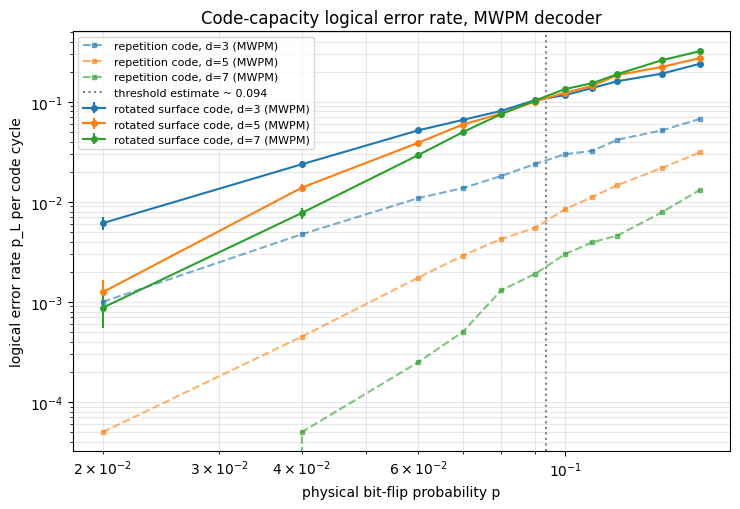

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 5.2))
colors = {3: "tab:blue", 5: "tab:orange", 7: "tab:green"}
for d in surf:
    ax.errorbar(P_GRID, pl_surf[d], yerr=err_surf[d], fmt="o-", ms=4, color=colors[d],
                label=f"rotated surface code, d={d} (MWPM)")
for d in rep:
    ax.plot(P_GRID, pl_rep[d], "s--", ms=3, color=colors[d], alpha=0.6, label=f"repetition code, d={d} (MWPM)")
if not np.isnan(th_35):
    ax.axvline(th_35, color="grey", ls=":", label=f"threshold estimate ~ {th_35:.3f}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("physical bit-flip probability p")
ax.set_ylabel("logical error rate p_L per code cycle")
ax.set_title("Code-capacity logical error rate, MWPM decoder")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

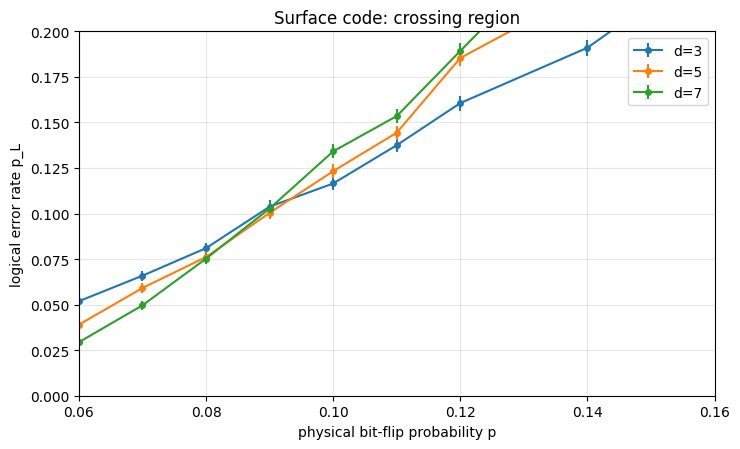

In [9]:
# Zoom on the crossing region, linear axes
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for d in surf:
    ax.errorbar(P_GRID, pl_surf[d], yerr=err_surf[d], fmt="o-", ms=4, color=colors[d], label=f"d={d}")
ax.set_xlim(0.06, 0.16); ax.set_ylim(0, 0.2)
ax.set_xlabel("physical bit-flip probability p"); ax.set_ylabel("logical error rate p_L")
ax.set_title("Surface code: crossing region"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [10]:
print("Summary")
print(f"  Surface code, logical error at p = 0.02: d=3 {pl_surf[3][0]:.5f}, d=5 {pl_surf[5][0]:.5f}, d=7 {pl_surf[7][0]:.6f}")
print(f"  Surface code, logical error at p = 0.10: d=3 {pl_surf[3][np.argmin(abs(P_GRID-0.10))]:.5f}, "
      f"d=5 {pl_surf[5][np.argmin(abs(P_GRID-0.10))]:.5f}, d=7 {pl_surf[7][np.argmin(abs(P_GRID-0.10))]:.5f}")
print(f"  Threshold (d=3/d=5 crossing): {th_35:.4f}; (d=5/d=7 crossing): {th_57:.4f}")
print(f"  Exact d=3 P_L at p=0.1 (enumeration): {pl_exact:.6f}")

Summary
  Surface code, logical error at p = 0.02: d=3 0.00613, d=5 0.00125, d=7 0.000875
  Surface code, logical error at p = 0.10: d=3 0.11650, d=5 0.12325, d=7 0.13412
  Threshold (d=3/d=5 crossing): 0.0937; (d=5/d=7 crossing): 0.0833
  Exact d=3 P_L at p=0.1 (enumeration): 0.119695


## Results
Measured in the executed notebook (code-capacity bit-flip noise, perfect syndrome measurement, MWPM decoder).

* **Codes simulated:** rotated planar surface codes with d = 3, 5, 7 (9, 25 and 49 data qubits; 4, 12 and 24 Z-checks), and bit-flip repetition codes with d = 3, 5, 7. No toric code was simulated.
* **Decoder check:** the d = 3 surface code corrects every single-qubit error. Exact enumeration of all 512 error patterns at p = 0.10 gives P_L = 0.119695 (256 patterns fail). Monte Carlo with 200000 shots gives 0.119015, consistent within about 1 standard error.
* **Repetition code, p = 0.10:** exact P_L = 0.02800 for d = 3, matching the closed form. Monte Carlo gives 0.02702 +/- 0.00036, which is about 2.7 standard errors low. I did not resolve this; the d = 5 and d = 7 checks agree within 1.3 standard errors.
* **Surface code, p = 0.02:** P_L = 0.00613 (d = 3), 0.00125 (d = 5), 0.00088 (d = 7).
* **Surface code, p = 0.10:** P_L = 0.11650 (d = 3), 0.12325 (d = 5), 0.13412 (d = 7). At this p the larger codes are no better than d = 3: d = 5 is higher by about 1.3 combined standard errors and d = 7 by about 3.4, so the crossing lies near or below 0.10.
* **Threshold crossings (8000 shots per point):** the d = 3 and d = 5 curves cross at p = 0.0937; the d = 5 and d = 7 curves cross at p = 0.0833.
* **Caveat on the threshold:** the two crossing estimates disagree by about 0.01, and the curves are close near the crossing. A preliminary run with 4000 shots per point gave crossings at 0.0797 and 0.0962, so the threshold is best quoted as roughly 0.08 to 0.10 for this simulation.
* **Repetition codes:** their curves are ordered d = 7 < d = 5 < d = 3 over the whole scanned range (0.02 to 0.16), with no crossing. This is consistent with the much higher repetition-code threshold for bit flips.
* **Scope:** code-capacity noise only, with no measurement errors, no circuit-level noise and no depolarising (Z) errors. The decoder is unweighted MWPM with networkx's exact matching.

## Conclusions
1. **The decoder is correct.** The distance-3 rotated surface code corrects every single-qubit X error, and its Monte Carlo logical error rate at p = 0.10 (0.1190 with 200,000 shots) matches exact enumeration of all 512 error patterns (0.1197).
2. **A threshold appears at roughly 8% to 10% physical error rate.** Below it, larger codes are better: at p = 0.02 the logical error rate falls from 0.0061 (d = 3) to 0.0013 (d = 5) and 0.0009 (d = 7). Above it the order reverses: at p = 0.10 it is 0.117, 0.123 and 0.134 for d = 3, 5 and 7. The measured crossings are 0.094 (d = 3 vs 5) and 0.083 (d = 5 vs 7); a preliminary run gave 0.080 and 0.096, so the data support a range, not a precise value. This is consistent with the roughly 10% threshold usually quoted for code-capacity noise with a minimum-weight matching decoder.
3. **A repetition code is better here, but it protects against less.** For bit-flip noise the repetition code shows no crossing in the 0.02 to 0.16 range and gives a lower logical error (0.0085 at d = 5 and p = 0.10). That is because it only has to defend against one error type, while the surface code also detects phase errors; this simulation only includes X noise, so the comparison favours the repetition code.
4. **Limits.** Code-capacity noise only (perfect measurements, X errors only, no circuit-level noise), minimum-weight matching rather than a production decoder, and no toric code. The repetition-code Monte Carlo at d = 3 and p = 0.10 (0.0270 ± 0.0004) is 2.7 standard errors below the exact value 0.0280; the decoder agrees with exact enumeration, so this is probably sampling variation, but a larger run was not done. Realistic thresholds with measurement errors are near 1%, not 10%.

**Takeaway for the interview:** the key idea is the threshold. Below it, adding qubits exponentially suppresses logical errors; above it, adding qubits makes things worse. Quoted thresholds depend heavily on the noise model.